# Proyecto 3 · Sentiment Analysis RELOADED
## Postura frente al aborto en comentarios de YouTube: *pro-vida* vs. *pro-aborto*

**Tema controversial:** aborto. Cada comentario (en español) se clasifica según la postura que expresa:

| Etiqueta | Significado |
|---|---|
| `vida` | Postura **pro-vida** (en contra del aborto) |
| `aborto` | Postura **pro-aborto** (a favor de la legalización / de la decisión de abortar) |
| `ninguno` | Sin postura identificable sobre el aborto (agradecimientos, mensajes de apoyo, ataques genéricos, comentarios fuera de tema…) |

**Contenido**

0. Configuración y carga de datos
1. Parte 1 · Preprocesamiento y línea base (BoW / TF-IDF + regresión logística)
2. Parte 2 · Ingeniería de características con POS y NER (spaCy) + BiLSTM
3. Parte 3 · Transformers (fine-tuning de BETO y RoBERTuito)
4. Parte 4 · Modelos híbridos (n-gramas de POS, n-gramas con entidades, embeddings mixtos + atención)
5. Parte 5 · Evaluación, comparación y análisis de errores
6. Reporte resumen

## 0. Configuración y carga de datos

In [1]:
import os, re, gc, math, random, time, warnings
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

import spacy
from langdetect import detect_langs, DetectorFactory

from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix)
from scipy.sparse import hstack

import transformers
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup)
transformers.logging.set_verbosity_error()

SEED = 42
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed(SEED)
DetectorFactory.seed = 0

LABELS = ["aborto", "vida", "ninguno"]           # orden fijo de las clases
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
COLORS = {"aborto": "#2A9D8F", "vida": "#E9A03B", "ninguno": "#8D99AE"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
if DEVICE == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.6)   # deja margen a otros procesos de la GPU

print("torch", torch.__version__, "| transformers", transformers.__version__, "| spaCy", spacy.__version__, "| dispositivo:", DEVICE)

torch 2.11.0+cu128 | transformers 5.20.2 | spaCy 3.8.18 | dispositivo: cuda


### 0.1 Recolección y etiquetado

**Fuente.** Comentarios públicos de YouTube descargados con la YouTube Data API v3 (`SentimentAnalysisTransformers/stance/collect.py`). Se hicieron 8 búsquedas en español con región México, 4 orientadas a cada postura (por ejemplo, *"marea verde aborto legal México"* y *"marcha por la vida aborto México"*), que devolvieron 117 videos. Cada video se clasificó por título y canal: 24 de contenido proelección, 28 provida, 57 mixtos (noticieros y debates) y 8 descartados por no tratar el tema. De cada video se bajaron hasta 500 comentarios principales, ordenados por relevancia: **6,665 comentarios de 96 videos** (4 tenían los comentarios desactivados). No se guardaron nombres de autores.

**Primer intento: etiquetar por fuente.** La idea inicial era asignar a cada comentario la postura del video donde aparece, reforzada con frases semilla explícitas (*"mi cuerpo, mi decisión"*, *"no al aborto"*, *"estoy a favor del aborto"*). Antes de usarlo se validó contra una muestra etiquetada a mano:

| Origen de la etiqueta | Acierto contra la etiqueta manual | Comentarios |
|---|---|---|
| Postura del video | 31 % | 36 |
| Frase semilla | 87 % | 15 |

La postura del video acierta menos que el azar: los videos proelección reciben sobre todo comentarios provida, que llegan a debatir. Además, el 37 % de los comentarios no expresa ninguna postura. Por eso se descartó el etiquetado por fuente y se etiquetó cada comentario por su contenido, en tres clases (`vida`, `aborto`, `ninguno`).

**Etiquetado.** 176 comentarios se etiquetaron a mano. Los otros 824 los etiquetó un modelo de lenguaje (Claude Haiku 5.5) con las mismas definiciones de clase, y se validó mezclando a ciegas los 176 manuales entre los que tenía que etiquetar:

| Medida contra las etiquetas manuales (n = 176) | Valor |
|---|---|
| Acuerdo | 77 % |
| Kappa de Cohen | 0.62 |
| Postura invertida (`vida` ↔ `aborto`) entre los 116 con postura | 6 % |

Casi todo el desacuerdo es entre `vida` y `ninguno`. Las etiquetas del modelo tienen, por lo tanto, un ruido cercano al 23 %, que pone un techo a las métricas de todos los clasificadores.

**Muestra.** 1,000 comentarios en español (verificado con `langdetect`), de al menos 5 palabras y sin duplicados: 200 de una primera muestra y 800 adicionales de hasta 150 palabras, con un máximo de 60 por video para que ningún video domine. Como los comentarios proelección son escasos (12 % de la primera muestra), entre los 800 se incluyeron todos los que contenían una frase semilla proelección (59); esto sesga ligeramente esa clase hacia posturas explícitas.


### 0.2 Carga del dataset
Los comentarios se encuentran en un único archivo (`comentarios_aborto.csv`) con tres columnas:
`comment_id`, `text` y `postura` (manual en 176 comentarios y de Claude Haiku en los otros 824; ver 0.1).

In [2]:
raw = pd.read_csv("comentarios_aborto.csv")
print("Comentarios únicos en el corpus:", len(raw))
print("Con etiqueta de postura       :", raw.postura.notna().sum())
print("Sin etiqueta                  :", raw.postura.isna().sum())
raw.head(3)

Comentarios únicos en el corpus: 1000
Con etiqueta de postura       : 1000
Sin etiqueta                  : 0


,comment_id,text,postura
0,UgyJa4b0R0GOAN90U2x4AaABAg,ya somos un chingo en este planeta!!!,aborto
1,Ugxbw-cyrdPP-6K9qEx4AaABAg,Pro-vida: el aborto es machismo😡😡😡😡😡\nYo: ._.,aborto
2,UgxHDB0V5BIcMj2gsKd4AaABAg,ABORTO LEGAL\nAl feto lo venden por Amazon,aborto


### 0.3 Preprocesamiento básico y verificación del idioma
Se limpia el texto de URLs, menciones y espacios repetidos. **No** se pasa a minúsculas ni se quitan emojis/puntuación en esta etapa:
los transformers los aprovechan y cada modelo clásico aplica su propia normalización. Después se verifica el idioma con `langdetect`,
porque BETO, RoBERTuito y los vectores de spaCy son **modelos en español**: un comentario en otro idioma degradaría sus predicciones.

In [3]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")

def clean_text(t):
    t = URL_RE.sub(" ", str(t))
    t = re.sub(r"@\w+", " ", t)          # menciones
    t = re.sub(r"\s+", " ", t)           # saltos de línea / espacios repetidos
    return t.strip()

raw["text_clean"] = raw.text.map(clean_text)
assert (raw.text_clean.str.len() > 0).all(), "hay comentarios vacíos tras la limpieza"
print("Textos duplicados:", raw.text_clean.duplicated().sum())

def detect_lang(t):
    try:
        best = detect_langs(t)[0]
        return best.lang, best.prob
    except Exception:
        return "??", 0.0

lang = raw.text_clean.map(detect_lang)
raw["lang"] = [l for l, _ in lang]
print("\nIdioma detectado:")
print(raw.lang.value_counts().to_string())

Textos duplicados: 0



Idioma detectado:
lang
es    998
uk      1
ca      1


**998 de 1,000** comentarios se detectan como español. Los otros dos son falsos positivos: *"Faltó leer el Catecismo de la Iglesia Católica..."* (detectado como catalán) y `#¿NOMBRE?` (ucraniano). Este último es un comentario que Excel convirtió en error de fórmula al editar el CSV durante el etiquetado, porque el original empieza con un guion; se conservó tal cual para que los resultados sean reproducibles con este CSV. No hace falta traducir ni filtrar: se usan modelos preentrenados en español (BETO, RoBERTuito y `es_core_news_md`).

### 0.4 Exploración de los datos
El aprendizaje supervisado (y toda la evaluación) usa únicamente los comentarios con etiqueta.

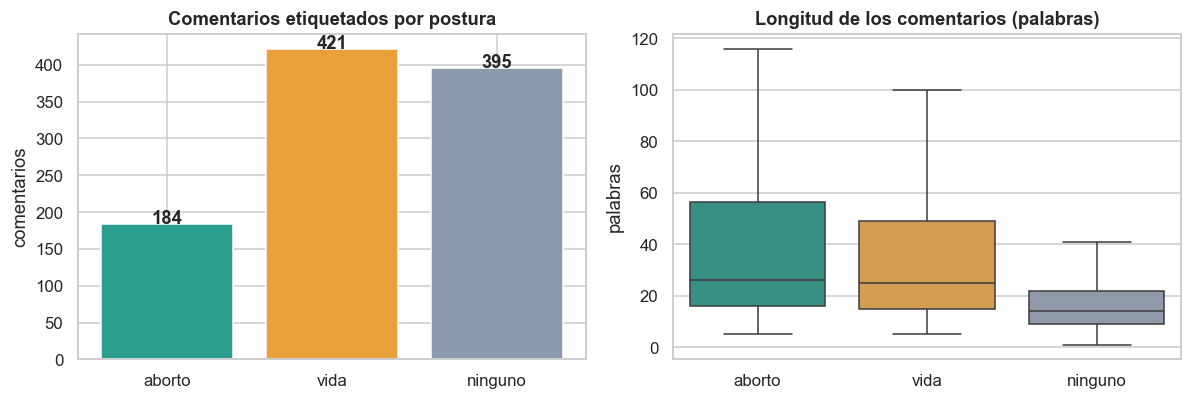

Comentarios etiquetados: 1000
         count  mean   std  min   25%   50%   75%     max
postura                                                  
aborto   184.0  46.3  88.0  5.0  16.0  26.0  56.2  1112.0
vida     421.0  38.3  37.1  5.0  15.0  25.0  49.0   264.0
ninguno  395.0  19.4  18.1  1.0   9.0  14.0  22.0   130.0


In [4]:
data = raw[raw.postura.notna()].reset_index(drop=True).copy()
data["y"] = data.postura.map(LABEL2ID)
data["n_palabras"] = data.text_clean.str.split().str.len()
y = data["y"].values

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
counts = data.postura.value_counts().reindex(LABELS)
axes[0].bar(counts.index, counts.values, color=[COLORS[l] for l in counts.index])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 0.5, str(v), ha="center", fontweight="bold")
axes[0].set_title("Comentarios etiquetados por postura"); axes[0].set_ylabel("comentarios")

sns.boxplot(data=data, x="postura", y="n_palabras", order=LABELS, palette=COLORS, ax=axes[1], showfliers=False)
axes[1].set_title("Longitud de los comentarios (palabras)"); axes[1].set_xlabel(""); axes[1].set_ylabel("palabras")
plt.tight_layout(); plt.show()

print("Comentarios etiquetados:", len(data))
print(data.groupby("postura").n_palabras.describe().round(1).reindex(LABELS))

In [5]:
pd.set_option("display.max_colwidth", 170)
ejemplos = pd.concat([g.sample(3, random_state=SEED) for _, g in data.groupby("postura")])[["postura", "text_clean"]]
ejemplos.assign(text_clean=ejemplos.text_clean.str.slice(0, 165)).reset_index(drop=True)

,postura,text_clean
0,aborto,Pues yo apoyo más la calidad de vida que la vida misma. Por eso estoy a favor del aborto
1,aborto,"Que aborten si quieren... pero con su dinero, no con el de papá gobierno que es de los impuestos de los mexicanos."
2,aborto,Aguanta el pañuelo naranja❤ Materias seguras y gratuitas ❤👌 :v
3,ninguno,"Cada vez que veo este video, me tiento😂"
4,ninguno,Ahí bibi por qué no eres una niña normal
5,ninguno,"Saben no se engañen,al tipo que asesinaron,era mason satanico,quexquieran engañarces otra cosa.asi que a observar bien antes que los engañe satanas."
6,vida,"Un católico apoya la vida, una buena persona es calificada por la moral con la que vive, no tanto por las cosas buenas que hacen, sus valores la califican como buena"
7,vida,Como pueden tener valor para acabar una vida que ahora disfrazan diciendo interrupción por favor
8,vida,Mi color favorito es el verde pero - PRO VIDAA 💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙💙


**Alcance y limitaciones del corpus.** El corpus tiene 1,000 comentarios etiquetados y está desbalanceado (`vida` 42 %, `ninguno` 40 %, `aborto` 18 %). Por eso:

* Se usa **validación cruzada estratificada de 5 pliegues** (mismos pliegues para todos los modelos) y se reportan predicciones *out-of-fold* sobre los 1,000 comentarios: cada comentario se evalúa exactamente una vez con un modelo que no lo vio.
* La métrica principal es **F1 macro** (trata igual a las tres clases), no la exactitud: predecir siempre `vida` ya da exactitud 0.42 con F1 macro de solo 0.20.
* Se reportan intervalos de confianza por *bootstrap*: diferencias de uno o dos puntos entre modelos **no son estadísticamente concluyentes**.
* Las clases se ponderan inversamente a su frecuencia en todos los modelos para no ignorar a `aborto`.
* **Ruido de etiqueta:** las etiquetas de Haiku coinciden 77 % con las manuales, así que parte de lo que se mide como error de un modelo es desacuerdo de etiqueta y las métricas tienen un techo por debajo de 1.

In [6]:
N_FOLDS = 5
FOLDS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))
for k, (tr, te) in enumerate(FOLDS):
    print(f"pliegue {k}: train={len(tr):>2}  test={len(te):>2}  clases en test={np.bincount(y[te], minlength=3)}")

RESULTS = {}      # nombre -> dict(familia, proba, pred, fold_f1)

def class_weights(yy):
    c = np.bincount(yy, minlength=3).astype(float)
    return len(yy) / (3.0 * np.maximum(c, 1))

def compute_metrics(yt, yp):
    p, r, f, _ = precision_recall_fscore_support(yt, yp, labels=[0, 1, 2], average="macro", zero_division=0)
    pc = precision_recall_fscore_support(yt, yp, labels=[0, 1, 2], average=None, zero_division=0)[2]
    return dict(acc=accuracy_score(yt, yp), prec=p, rec=r, f1=f, f1_aborto=pc[0], f1_vida=pc[1], f1_ninguno=pc[2])

def boot_ci(yt, yp, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(yt), len(yt))
        vals.append(f1_score(yt[idx], yp[idx], average="macro", labels=[0, 1, 2], zero_division=0))
    return np.percentile(vals, [2.5, 97.5])

def evaluate(name, family, fit_predict):
    """fit_predict(train_idx, test_idx) -> matriz (n_test, 3) de probabilidades."""
    t0 = time.time()
    proba = np.zeros((len(y), 3)); fold_f1 = []
    for k, (tr, te) in enumerate(FOLDS):
        set_seed(SEED + k)
        P = fit_predict(tr, te)
        proba[te] = P
        fold_f1.append(f1_score(y[te], P.argmax(1), average="macro", labels=[0, 1, 2], zero_division=0))
    pred = proba.argmax(1)
    RESULTS[name] = dict(family=family, proba=proba, pred=pred, fold_f1=np.array(fold_f1))
    m = compute_metrics(y, pred)
    print(f"{name:<44} acc={m['acc']:.3f}  F1 macro={m['f1']:.3f}  (por pliegue {np.mean(fold_f1):.3f} ± {np.std(fold_f1):.3f})  [{time.time()-t0:.0f}s]")

def results_table(names=None):
    rows = []
    for n, r in RESULTS.items():
        if names is not None and n not in names:
            continue
        m = compute_metrics(y, r["pred"]); lo, hi = boot_ci(y, r["pred"])
        rows.append({"Modelo": n, "Familia": r["family"],
                     "Accuracy": m["acc"], "Precision (macro)": m["prec"], "Recall (macro)": m["rec"], "F1 (macro)": m["f1"],
                     "F1 por pliegue": f"{r['fold_f1'].mean():.3f} ± {r['fold_f1'].std():.3f}",
                     "IC 95 % F1 (bootstrap)": f"[{lo:.2f}, {hi:.2f}]",
                     "F1 aborto": m["f1_aborto"], "F1 vida": m["f1_vida"], "F1 ninguno": m["f1_ninguno"]})
    t = pd.DataFrame(rows).set_index("Modelo")
    num = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "F1 aborto", "F1 vida", "F1 ninguno"]
    return t.style.format({c: "{:.3f}" for c in num}).background_gradient(subset=["F1 (macro)"], cmap="YlGn", vmin=0.2, vmax=0.8)

pliegue 0: train=800  test=200  clases en test=[37 84 79]
pliegue 1: train=800  test=200  clases en test=[37 84 79]
pliegue 2: train=800  test=200  clases en test=[37 84 79]
pliegue 3: train=800  test=200  clases en test=[37 84 79]
pliegue 4: train=800  test=200  clases en test=[36 85 79]


## Parte 1 · Línea base: BoW / TF-IDF + regresión logística
Primero se fija una referencia mínima (clasificador que siempre predice la clase mayoritaria) y después dos representaciones
tradicionales: **bolsa de palabras** (conteos de unigramas) y **TF-IDF con unigramas + bigramas**. Ambas alimentan una regresión logística con
`class_weight="balanced"`. Los vectorizadores se ajustan **dentro de cada pliegue** (solo con el train) para no filtrar información del test.

In [7]:
X_text = data.text_clean.values

def sk_fit_predict(make_model, X):
    def fp(tr, te):
        m = make_model()
        m.fit(X[tr], y[tr])
        return m.predict_proba(X[te])
    return fp

evaluate("Mayoría (referencia)", "Línea base", sk_fit_predict(lambda: DummyClassifier(strategy="prior"), X_text))

evaluate("BoW (unigramas) + LR", "Línea base", sk_fit_predict(
    lambda: make_pipeline(CountVectorizer(lowercase=True),
                          LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000)), X_text))

evaluate("TF-IDF (1-2 gramas) + LR", "Línea base", sk_fit_predict(
    lambda: make_pipeline(TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True),
                          LogisticRegression(C=10.0, class_weight="balanced", max_iter=3000)), X_text))

Mayoría (referencia)                         acc=0.421  F1 macro=0.198  (por pliegue 0.198 ± 0.001)  [0s]


BoW (unigramas) + LR                         acc=0.623  F1 macro=0.592  (por pliegue 0.591 ± 0.037)  [1s]


TF-IDF (1-2 gramas) + LR                     acc=0.618  F1 macro=0.595  (por pliegue 0.595 ± 0.026)  [1s]


**¿Qué palabras pesan más?** Coeficientes del modelo TF-IDF + LR ajustado con todos los comentarios etiquetados (solo para interpretación, no para evaluar).

In [8]:
vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
Xall = vec.fit_transform(X_text)
lr_all = LogisticRegression(C=10.0, class_weight="balanced", max_iter=3000).fit(Xall, y)
names = np.array(vec.get_feature_names_out())
top = {LABELS[c]: list(names[np.argsort(-lr_all.coef_[c])[:10]]) for c in range(3)}
pd.DataFrame(top)

,aborto,vida,ninguno
0,aborto,la vida,video
1,favor del,vida,veo
2,cada,dios,pelo
3,pro,contra,el pelo
4,aborto legal,matar,señor
5,legal,contra del,también peores
6,gratuito,hay,pon
7,cada quien,que,pon también
8,estoy,en contra,por favor
9,estoy favor,estas,se la


### Comentarios · Línea base
* **Referencia:** predecir siempre `vida` da exactitud 0.421 y F1 macro 0.198; cualquier modelo útil debe superar ese F1.
* **BoW + LR** (F1 macro 0.592) y **TF-IDF 1-2 gramas + LR** (0.595) quedan empatados, con intervalos casi idénticos ([0.56, 0.62] y [0.56, 0.63]). Con 800 comentarios de entrenamiento por pliegue los bigramas ya no sobreajustan. TF-IDF es mejor en `aborto` (F1 0.51 frente a 0.47) y BoW en `ninguno` (0.70 frente a 0.61): TF-IDF manda a `vida` el 37 % de los `ninguno` (ver 5.1).
* **Lectura de los coeficientes:** reflejan contenido de postura. Para `aborto` pesan *favor del*, *aborto legal*, *gratuito*, *cada quien* y *estoy favor*; para `vida`, *la vida*, *dios*, *matar* y *en contra*; para `ninguno`, palabras sobre el video (*video*, *veo*, *pelo*, *por favor*). Parte de la señal de `aborto` son frases explícitas como *aborto legal* o *estoy a favor*, las mismas que se usaron para priorizar 59 comentarios de la muestra (0.1), así que ese resultado puede estar favorecido por la selección.

## Parte 2 · Ingeniería de características con POS y NER
Se usa **spaCy** (`es_core_news_md`) para obtener, por cada token, su etiqueta gramatical universal (**POS**), su tipo de entidad nombrada (**NER**: `PER`, `LOC`, `ORG`, `MISC`, o `O` si no pertenece a una entidad)
y su vector de palabra de 300 dimensiones (vectores estáticos incluidos en el modelo).

In [9]:
nlp = spacy.load("es_core_news_md")
docs = list(nlp.pipe(data.text_clean.tolist(), batch_size=32))

UPOS = ["ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM", "PART", "PRON", "PROPN", "PUNCT", "SCONJ", "SYM", "VERB", "X"]
NERT = ["O", "PER", "LOC", "ORG", "MISC"]
POS2ID = {p: i for i, p in enumerate(UPOS)}
NER2ID = {n: i for i, n in enumerate(NERT)}

def replace_entities(toks, keep=()):
    """Sustituye cada entidad por ENT_<tipo> (salvo los tipos en `keep`)."""
    out = []
    for t in toks:
        if t.ent_type_ and t.ent_type_ not in keep:
            if t.ent_iob_ == "B":
                out.append("ENT_" + t.ent_type_)
        else:
            out.append(t.text)
    return " ".join(out)

def analyze(doc):
    toks = [t for t in doc if not t.is_space]
    return dict(
        words=[t.text for t in toks],
        pos=[t.pos_ if t.pos_ in POS2ID else "X" for t in toks],
        ner=[t.ent_type_ if t.ent_type_ in NER2ID else "O" for t in toks],
        vec=np.stack([t.vector for t in toks]).astype(np.float32),
        ents=[(e.text, e.label_) for e in doc.ents],
        text_ent=replace_entities(toks),
        text_ent_nomisc=replace_entities(toks, keep=("MISC",)),
    )

A = [analyze(d) for d in docs]
for a in A:
    a["pos_id"] = [POS2ID[p] for p in a["pos"]]
    a["ner_id"] = [NER2ID[n] for n in a["ner"]]

data["pos_str"] = [" ".join(a["pos"]) for a in A]
data["text_ent"] = [a["text_ent"] for a in A]
data["text_ent_nomisc"] = [a["text_ent_nomisc"] for a in A]
data["n_ents"] = [len(a["ents"]) for a in A]

i = data.index[data.n_ents > 0][0]
print("Original   :", data.text_clean[i][:150])
print("POS        :", " ".join(A[i]["pos"][:25]))
print("Entidades  :", A[i]["ents"])
print("Reemplazo  :", data.text_ent[i][:150])

Original   : ABORTO LEGAL Al feto lo venden por Amazon
POS        : NOUN PUNCT ADP NOUN PRON VERB ADP PROPN
Entidades  : [('LEGAL', 'ORG'), ('Amazon', 'PER')]
Reemplazo  : ABORTO ENT_ORG Al feto lo venden por ENT_PER


### 2.1 Distribución de POS y NER por postura

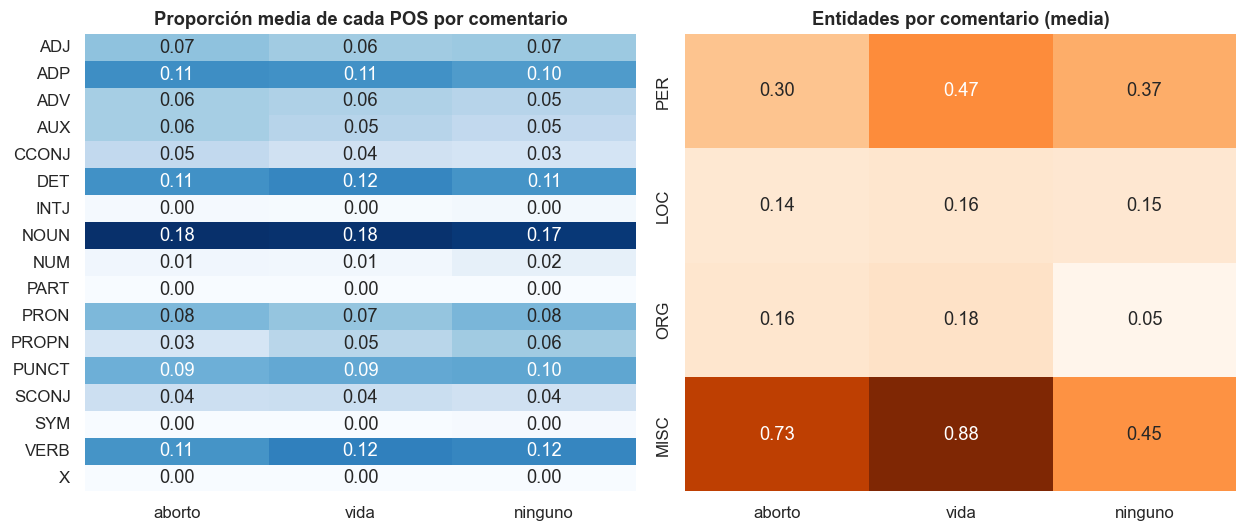

,aborto,vida,ninguno
0,Cynthia (MISC),Dios (MISC),Dios (MISC)
1,Argentina (LOC),Dios (PER),Lupe (PER)
2,No (MISC),Jesús (PER),Dios (PER)
3,Lupe (PER),No (MISC),Argentina (LOC)
4,Dios (MISC),España (LOC),Pasty (PER)


In [10]:
pos_rows = []
for a, c in zip(A, data.postura):
    n = len(a["pos"])
    cnt = np.bincount([POS2ID[p] for p in a["pos"]], minlength=len(UPOS)) / n
    pos_rows.append(dict(postura=c, **dict(zip(UPOS, cnt))))
pos_dist = pd.DataFrame(pos_rows).groupby("postura")[UPOS].mean().reindex(LABELS).T

ner_rows = []
for a, c in zip(A, data.postura):
    cnt = pd.Series([lab for _, lab in a["ents"]]).value_counts()
    ner_rows.append(dict(postura=c, **{k: cnt.get(k, 0) for k in NERT[1:]}))
ner_dist = pd.DataFrame(ner_rows).groupby("postura")[NERT[1:]].mean().reindex(LABELS).T

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), gridspec_kw={"width_ratios": [1, 1]})
sns.heatmap(pos_dist, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Proporción media de cada POS por comentario"); axes[0].set_xlabel("")
sns.heatmap(ner_dist, annot=True, fmt=".2f", cmap="Oranges", cbar=False, ax=axes[1])
axes[1].set_title("Entidades por comentario (media)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

ent_tbl = {}
for c in LABELS:
    ents = [e for a, p in zip(A, data.postura) if p == c for e in a["ents"]]
    ent_tbl[c] = [f"{t} ({l})" for (t, l), _ in pd.Series(ents).value_counts().head(5).items()] if ents else []
pd.DataFrame({k: pd.Series(v) for k, v in ent_tbl.items()}).fillna("")

### 2.2 Estrategia 1 · Conteos de POS/NER por comentario
Vector de 22 dimensiones: proporción de cada POS (17), número de entidades de cada tipo (4) y log de la longitud. Se estandariza y se clasifica con regresión logística.

In [11]:
def tag_count_features(a):
    n = len(a["words"])
    pos = np.bincount(a["pos_id"], minlength=len(UPOS)) / n
    ent = np.bincount([NER2ID[l] for _, l in a["ents"]], minlength=len(NERT))[1:]
    return np.concatenate([pos, ent, [np.log1p(n)]])

X_cnt = np.stack([tag_count_features(a) for a in A])
evaluate("Conteos POS/NER + LR", "POS/NER", sk_fit_predict(
    lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, class_weight="balanced", max_iter=3000)), X_cnt))

Conteos POS/NER + LR                         acc=0.484  F1 macro=0.470  (por pliegue 0.470 ± 0.017)  [0s]


### 2.3 Estrategias 2 y 3 · BiLSTM con embeddings de etiquetas concatenados a los vectores de palabra
Cada token es la concatenación de su **vector de palabra** (300 d, congelado) con un **embedding entrenable de su POS** (16 d) y de su **etiqueta NER** (8 d).
La secuencia pasa por una **BiLSTM** (64 unidades por dirección), *max-pooling* sobre el tiempo, *dropout* y una capa lineal.
Se comparan tres variantes (solo palabras, palabras + POS, palabras + POS + NER). Para reducir la varianza, cada pliegue promedia las probabilidades de 3 inicializaciones.

In [12]:
MAX_TOK = 100
EPOCHS_LSTM = 40
N_SEEDS = 3

class TagBiLSTM(nn.Module):
    def __init__(self, use_pos, use_ner, emb_dim=300, pos_dim=16, ner_dim=8, hid=64, drop=0.5):
        super().__init__()
        self.use_pos, self.use_ner = use_pos, use_ner
        self.pos_emb = nn.Embedding(len(UPOS), pos_dim) if use_pos else None
        self.ner_emb = nn.Embedding(len(NERT), ner_dim) if use_ner else None
        d = emb_dim + (pos_dim if use_pos else 0) + (ner_dim if use_ner else 0)
        self.lstm = nn.LSTM(d, hid, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(drop)
        self.out = nn.Linear(2 * hid, 3)

    def forward(self, vec, pos, ner, lengths):
        x = [vec]
        if self.use_pos: x.append(self.pos_emb(pos))
        if self.use_ner: x.append(self.ner_emb(ner))
        x = self.drop(torch.cat(x, -1))
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=vec.shape[1])
        mask = torch.arange(h.shape[1], device=h.device)[None, :] < lengths.to(h.device)[:, None]
        h = h.masked_fill(~mask.unsqueeze(-1), -1e9)
        return self.out(self.drop(h.max(1).values))

def seq_batch(ids):
    L = [min(len(A[i]["words"]), MAX_TOK) for i in ids]
    T = max(L)
    vec = torch.zeros(len(ids), T, 300); pos = torch.zeros(len(ids), T, dtype=torch.long); ner = torch.zeros_like(pos)
    for b, i in enumerate(ids):
        l = L[b]
        vec[b, :l] = torch.from_numpy(A[i]["vec"][:l])
        pos[b, :l] = torch.tensor(A[i]["pos_id"][:l]); ner[b, :l] = torch.tensor(A[i]["ner_id"][:l])
    return vec.to(DEVICE), pos.to(DEVICE), ner.to(DEVICE), torch.tensor(L)   # longitudes en CPU (pack_padded_sequence)

def bilstm_fit_predict(use_pos, use_ner):
    def fp(tr, te):
        P = np.zeros((len(te), 3))
        w = torch.tensor(class_weights(y[tr]), dtype=torch.float32, device=DEVICE)
        for s in range(N_SEEDS):
            set_seed(SEED + 100 * s)
            model = TagBiLSTM(use_pos, use_ner).to(DEVICE)
            opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-4)
            loss_fn = nn.CrossEntropyLoss(weight=w)
            for ep in range(EPOCHS_LSTM):
                model.train()
                perm = np.random.permutation(tr)
                for i in range(0, len(perm), 16):
                    b = perm[i:i + 16]
                    loss = loss_fn(model(*seq_batch(b)), torch.tensor(y[b], device=DEVICE))
                    opt.zero_grad(); loss.backward(); opt.step()
            model.eval()
            with torch.no_grad():
                P += torch.softmax(model(*seq_batch(te)), -1).cpu().numpy()
        return P / N_SEEDS
    return fp

evaluate("BiLSTM + vectores de palabra", "POS/NER", bilstm_fit_predict(False, False))
evaluate("BiLSTM + vectores + POS", "POS/NER", bilstm_fit_predict(True, False))
evaluate("BiLSTM + vectores + POS + NER", "POS/NER", bilstm_fit_predict(True, True))

BiLSTM + vectores de palabra                 acc=0.609  F1 macro=0.589  (por pliegue 0.587 ± 0.026)  [746s]


BiLSTM + vectores + POS                      acc=0.612  F1 macro=0.586  (por pliegue 0.585 ± 0.033)  [697s]


BiLSTM + vectores + POS + NER                acc=0.603  F1 macro=0.579  (por pliegue 0.578 ± 0.038)  [690s]


In [13]:
part2 = ["Mayoría (referencia)", "TF-IDF (1-2 gramas) + LR", "Conteos POS/NER + LR",
         "BiLSTM + vectores de palabra", "BiLSTM + vectores + POS", "BiLSTM + vectores + POS + NER"]
results_table(part2)

,Familia,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 por pliegue,IC 95 % F1 (bootstrap),F1 aborto,F1 vida,F1 ninguno
Modelo,,,,,,,,,,
Mayoría (referencia),Línea base,0.421,0.140,0.333,0.198,0.198 ± 0.001,"[0.19, 0.21]",0.000,0.593,0.000
TF-IDF (1-2 gramas) + LR,Línea base,0.618,0.611,0.590,0.595,0.595 ± 0.026,"[0.56, 0.63]",0.512,0.662,0.611
Conteos POS/NER + LR,POS/NER,0.484,0.482,0.492,0.470,0.470 ± 0.017,"[0.44, 0.50]",0.370,0.454,0.585
BiLSTM + vectores de palabra,POS/NER,0.609,0.587,0.598,0.589,0.587 ± 0.026,"[0.56, 0.62]",0.503,0.571,0.692
BiLSTM + vectores + POS,POS/NER,0.612,0.588,0.593,0.586,0.585 ± 0.033,"[0.55, 0.62]",0.478,0.586,0.694
BiLSTM + vectores + POS + NER,POS/NER,0.603,0.578,0.590,0.579,0.578 ± 0.038,"[0.55, 0.61]",0.475,0.562,0.699


### Comentarios · POS y NER
* **POS:** la proporción de cada categoría gramatical es prácticamente igual en las tres clases (diferencias de 0.01 o menos): la sintaxis casi no distingue posturas.
* **NER:** los comentarios `ninguno` tienen menos entidades `ORG` (0.05 por comentario frente a 0.16 a 0.18) y `MISC` (0.45 frente a 0.73 a 0.88), y `vida` tiene más `PER` (0.47), en buena parte *Dios* y *Jesús*. *Dios* es la entidad más frecuente en las tres clases y spaCy la etiqueta a veces como `PER` y a veces como `MISC`: el modelo, entrenado con noticias, es ruidoso en este dominio (*LEGAL* como `ORG`, *Amazon* como `PER`).
* **Modelos:** los conteos de POS/NER (22 números por comentario) alcanzan F1 0.470, muy por encima de la referencia pero 12 puntos debajo de BoW. En la BiLSTM, añadir etiquetas **no ayuda**: solo vectores 0.589, + POS 0.586, + POS + NER 0.579, diferencias dentro de la variación entre pliegues (± 0.03). Con los primeros 81 comentarios la tendencia parecía creciente, pero no se sostuvo ni al repetir la corrida en otra máquina ni con 1,000 comentarios.
* La BiLSTM con POS + NER es la que mejor reconoce `ninguno` (recall 75 %), pero la que más falla en `vida` (recall 50 %; el 30 % se va a `ninguno`).

## Parte 3 · Modelos basados en Transformers (fine-tuning)
Se ajustan (*fine-tuning* completo, clasificación de 3 clases) dos modelos preentrenados **en español**:

* **BETO** (`dccuchile/bert-base-spanish-wwm-cased`): BERT entrenado con texto general en español.
* **RoBERTuito** (`pysentimiento/robertuito-base-uncased`): RoBERTa entrenado con tweets en español, es decir, lenguaje de redes sociales como el de estos comentarios (equivalente en español de BERTweet).

Configuración: AdamW (lr = 3e-5, *weight decay* 0.01), *warm-up* lineal del 10 %, lote de 8, 8 épocas, longitud máxima de 128 *subwords*,
pérdida de entropía cruzada ponderada por clase y modelo reinicializado desde el preentrenado en cada pliegue.

In [14]:
MAX_LEN = 128
EPOCHS_HF = 8
LR_ENC, LR_HEAD, BATCH = 3e-5, 1e-3, 8
BETO = "dccuchile/bert-base-spanish-wwm-cased"
ROBERTUITO = "pysentimiento/robertuito-base-uncased"

def collate(items, pad_id):
    B, T = len(items), max(len(it["input_ids"]) for it in items)
    ids = torch.full((B, T), pad_id, dtype=torch.long)
    att = torch.zeros(B, T, dtype=torch.long)
    pos = torch.zeros(B, T, dtype=torch.long); ner = torch.zeros(B, T, dtype=torch.long)
    for b, it in enumerate(items):
        n = len(it["input_ids"])
        ids[b, :n] = torch.tensor(it["input_ids"]); att[b, :n] = 1
        if "pos_ids" in it:
            pos[b, :n] = torch.tensor(it["pos_ids"]); ner[b, :n] = torch.tensor(it["ner_ids"])
    return {"input_ids": ids.to(DEVICE), "attention_mask": att.to(DEVICE), "pos_ids": pos.to(DEVICE), "ner_ids": ner.to(DEVICE)}

def encode_plain(tok):
    return [{"input_ids": tok(t, truncation=True, max_length=MAX_LEN)["input_ids"]} for t in data.text_clean]

class HFClassifier(nn.Module):
    """Fine-tuning estándar: encoder + cabeza de clasificación."""
    def __init__(self, name):
        super().__init__()
        self.hf = AutoModelForSequenceClassification.from_pretrained(name, num_labels=3)
    def forward(self, batch):
        out = self.hf(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
        return out.logits, None
    def param_groups(self, lr, head_lr):
        return [{"params": self.hf.parameters(), "lr": lr}]

def transformer_fit_predict(make_model, enc, pad_id, att_store=None):
    def fp(tr, te):
        model = make_model().to(DEVICE)
        opt = torch.optim.AdamW(model.param_groups(LR_ENC, LR_HEAD), weight_decay=0.01)
        steps = EPOCHS_HF * math.ceil(len(tr) / BATCH)
        sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
        loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_weights(y[tr]), dtype=torch.float32, device=DEVICE))
        for ep in range(EPOCHS_HF):
            model.train()
            perm = np.random.permutation(tr)
            for i in range(0, len(perm), BATCH):
                b = perm[i:i + BATCH]
                logits, _ = model(collate([enc[j] for j in b], pad_id))
                loss = loss_fn(logits, torch.tensor(y[b], device=DEVICE))
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step(); sched.step()
        model.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(te), 16):
                b = te[i:i + 16]
                logits, extra = model(collate([enc[j] for j in b], pad_id))
                out.append(torch.softmax(logits, -1).cpu().numpy())
                if extra is not None and att_store is not None:
                    for r, j in enumerate(b):
                        n = len(enc[j]["input_ids"])
                        att_store[j] = dict(word_ids=enc[j]["word_ids"], alpha=extra["att"][r, :n].cpu().numpy(),
                                            gate=None if extra["gate"] is None else float(extra["gate"][r, :n].mean()))
        del model, opt
        gc.collect()
        if DEVICE == "mps": torch.mps.empty_cache()
        return np.concatenate(out)
    return fp

tok_beto = AutoTokenizer.from_pretrained(BETO)
tok_rob = AutoTokenizer.from_pretrained(ROBERTUITO)
enc_beto, enc_rob = encode_plain(tok_beto), encode_plain(tok_rob)
n_trunc = sum(len(tok_beto(t)["input_ids"]) > MAX_LEN for t in data.text_clean)
print(f"Comentarios truncados a {MAX_LEN} subwords (BETO): {n_trunc} de {len(data)}")

evaluate("BETO (fine-tuning)", "Transformer",
         transformer_fit_predict(lambda: HFClassifier(BETO), enc_beto, tok_beto.pad_token_id))
evaluate("RoBERTuito (fine-tuning)", "Transformer",
         transformer_fit_predict(lambda: HFClassifier(ROBERTUITO), enc_rob, tok_rob.pad_token_id))

Comentarios truncados a 128 subwords (BETO): 48 de 1000


W1110 14:06:33.151787 6756 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


BETO (fine-tuning)                           acc=0.659  F1 macro=0.632  (por pliegue 0.631 ± 0.031)  [427s]


RoBERTuito (fine-tuning)                     acc=0.650  F1 macro=0.635  (por pliegue 0.635 ± 0.010)  [416s]


In [15]:
results_table(["Mayoría (referencia)", "TF-IDF (1-2 gramas) + LR", "BiLSTM + vectores + POS + NER",
               "BETO (fine-tuning)", "RoBERTuito (fine-tuning)"])

,Familia,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 por pliegue,IC 95 % F1 (bootstrap),F1 aborto,F1 vida,F1 ninguno
Modelo,,,,,,,,,,
Mayoría (referencia),Línea base,0.421,0.140,0.333,0.198,0.198 ± 0.001,"[0.19, 0.21]",0.000,0.593,0.000
TF-IDF (1-2 gramas) + LR,Línea base,0.618,0.611,0.590,0.595,0.595 ± 0.026,"[0.56, 0.63]",0.512,0.662,0.611
BiLSTM + vectores + POS + NER,POS/NER,0.603,0.578,0.590,0.579,0.578 ± 0.038,"[0.55, 0.61]",0.475,0.562,0.699
BETO (fine-tuning),Transformer,0.659,0.635,0.630,0.632,0.631 ± 0.031,"[0.60, 0.66]",0.515,0.686,0.695
RoBERTuito (fine-tuning),Transformer,0.650,0.630,0.648,0.635,0.635 ± 0.010,"[0.60, 0.67]",0.548,0.654,0.702


### Comentarios · Transformers
* **BETO** (F1 macro 0.632, exactitud 0.659) y **RoBERTuito** (0.635, 0.650) son los mejores modelos de una sola familia, unos 4 puntos por encima de BoW, TF-IDF y la BiLSTM. Sus intervalos ([0.60, 0.66] y [0.60, 0.67]) apenas se traslapan con los de la línea base ([0.56, 0.63]): la ventaja es modesta, pero aparece en los cuatro modelos basados en Transformers.
* RoBERTuito, preentrenado con tuits, es el que mejor detecta `aborto` (recall 64 %, F1 0.55), a costa de mandar a `aborto` el 20 % de los `vida`. BETO es más conservador (recall de `aborto` 50 %) y mejor en `vida` (70 %). En F1 macro empatan.
* Con los primeros 81 comentarios ninguno de los dos acertaba un solo `aborto`; con 184 ejemplos de esa clase ya la aprenden. El cuello de botella era el tamaño del corpus, no la arquitectura.
* 48 de los 1,000 comentarios se truncan a 128 *subwords*.

## Parte 4 · Modelos híbridos
Se implementan las **tres** variantes propuestas en el enunciado.

### 4.1 N-gramas sintácticos (POS-tagged n-grams)
En lugar de palabras se usan **secuencias de etiquetas POS** (p. ej. `PRON VERB SCONJ`) y se extraen 1-, 2- y 3-gramas de etiquetas. Capturan patrones sintácticos (estilo del comentario) y reducen la dispersión. También se combinan con los n-gramas de palabras.

In [16]:
def lr_tfidf(ngram, lowercase, token_pattern=r"(?u)\b\w\w+\b", C=10.0):
    return make_pipeline(TfidfVectorizer(lowercase=lowercase, ngram_range=ngram, sublinear_tf=True, token_pattern=token_pattern),
                         LogisticRegression(C=C, class_weight="balanced", max_iter=3000))

evaluate("POS 1-3 gramas + LR", "Híbrido", sk_fit_predict(lambda: lr_tfidf((1, 3), False, r"\S+"), data.pos_str.values))

class WordPlusPOS:
    """TF-IDF de palabras (1-2) y de POS (1-3) concatenados + LR."""
    def __init__(self, word_col="text_clean", C=10.0):
        self.word_col, self.C = word_col, C
        self.vw = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
        self.vp = TfidfVectorizer(lowercase=False, ngram_range=(1, 3), sublinear_tf=True, token_pattern=r"\S+")
        self.lr = LogisticRegression(C=C, class_weight="balanced", max_iter=3000)
    def _x(self, idx, fit):
        w, p = data[self.word_col].values[idx], data.pos_str.values[idx]
        if fit: return hstack([self.vw.fit_transform(w), self.vp.fit_transform(p)]).tocsr()
        return hstack([self.vw.transform(w), self.vp.transform(p)]).tocsr()
    def fit(self, idx, yy): self.lr.fit(self._x(idx, True), yy); return self
    def predict_proba(self, idx): return self.lr.predict_proba(self._x(idx, False))

def combo_fit_predict(word_col):
    def fp(tr, te):
        m = WordPlusPOS(word_col).fit(tr, y[tr])
        return m.predict_proba(te)
    return fp

evaluate("Palabras 1-2g + POS 1-3g + LR", "Híbrido", combo_fit_predict("text_clean"))

POS 1-3 gramas + LR                          acc=0.529  F1 macro=0.504  (por pliegue 0.503 ± 0.035)  [0s]


Palabras 1-2g + POS 1-3g + LR                acc=0.633  F1 macro=0.607  (por pliegue 0.607 ± 0.047)  [1s]


### 4.2 N-gramas con entidades sustituidas (NER-tag-enhanced n-grams)
Cada entidad se reemplaza por su tipo (`Patricia` → `ENT_PER`, `México` → `ENT_LOC`) antes de extraer los n-gramas, para generalizar sobre nombres propios.
Se prueban dos versiones: sustituyendo **todos** los tipos y sustituyendo solo `PER`/`LOC`/`ORG` (conservando `MISC`, donde spaCy suele colocar términos como *Dios*).

In [17]:
evaluate("N-gramas con entidades (ENT_*) + LR", "Híbrido", sk_fit_predict(lambda: lr_tfidf((1, 2), True), data.text_ent.values))
evaluate("N-gramas con entidades, sin MISC + LR", "Híbrido", sk_fit_predict(lambda: lr_tfidf((1, 2), True), data.text_ent_nomisc.values))
evaluate("Entidades (sin MISC) + POS 1-3g + LR", "Híbrido", combo_fit_predict("text_ent_nomisc"))

ex = data.index[data.n_ents >= 2][:3]
for i in ex:
    print("ORIG:", data.text_clean[i][:140]); print("ENT :", data.text_ent[i][:140]); print()

N-gramas con entidades (ENT_*) + LR          acc=0.613  F1 macro=0.590  (por pliegue 0.590 ± 0.025)  [1s]


N-gramas con entidades, sin MISC + LR        acc=0.609  F1 macro=0.586  (por pliegue 0.586 ± 0.027)  [1s]


Entidades (sin MISC) + POS 1-3g + LR         acc=0.633  F1 macro=0.609  (por pliegue 0.608 ± 0.039)  [1s]
ORIG: ABORTO LEGAL Al feto lo venden por Amazon
ENT : ABORTO ENT_ORG Al feto lo venden por ENT_PER

ORIG: A favor del aborto. Y ¿Por qué a favor? Antes que nada, quiero aclarar: No soy feminista ni nada por el estilo. Ahora sí. Yo estoy a favor d
ENT : A favor del aborto . ENT_MISC Por qué a favor ? Antes que nada , quiero aclarar : No soy feminista ni nada por el estilo . ENT_MISC sí . Yo 

ORIG: De las pro vida me gustaron mucho los argumentos de Lupe, apesar que estoy a favor del aborto. Y de los pro aborto muy super de acuerdo con 
ENT : De las pro vida me gustaron mucho los argumentos de ENT_PER , apesar que estoy a favor del aborto . Y de los pro aborto muy super de acuerdo



### 4.3 Embeddings mixtos + atención (BETO + etiquetas POS/NER)
Arquitectura de dos flujos que se entrena de extremo a extremo:

1. **Flujo contextual:** BETO produce un vector contextual de 768 d por *subword*.
2. **Flujo estructural:** los POS y NER de cada palabra (alineados a sus *subwords*) pasan por embeddings entrenables (32 d y 16 d) y una **BiGRU**; el resultado se proyecta a 768 d.
3. **Compuerta (*gating*):** `g = σ(W·[h; s])`, `f = g ⊙ h + (1 − g) ⊙ s`; el modelo decide por dimensión cuánto confiar en el flujo contextual y cuánto en el estructural.
4. **Atención aditiva:** `α = softmax(vᵀ tanh(W f))` pondera los tokens; el vector ponderado alimenta el clasificador.

Como control, se entrena también la misma arquitectura **sin** el flujo estructural (solo BETO + *pooling* por atención), para saber si una mejora viene de las etiquetas o del *pooling*.

In [18]:
class HybridTagAttention(nn.Module):
    def __init__(self, name, use_tags=True, tag_pos=32, tag_ner=16, gru=64, drop=0.3):
        super().__init__()
        self.use_tags = use_tags
        self.enc = AutoModel.from_pretrained(name)
        H = self.enc.config.hidden_size
        if use_tags:
            self.pos_emb = nn.Embedding(len(UPOS) + 1, tag_pos, padding_idx=0)     # 0 = [CLS]/[SEP]/relleno
            self.ner_emb = nn.Embedding(len(NERT) + 1, tag_ner, padding_idx=0)
            self.tag_rnn = nn.GRU(tag_pos + tag_ner, gru, batch_first=True, bidirectional=True)
            self.tag_proj = nn.Linear(2 * gru, H)
            self.gate = nn.Linear(2 * H, H)
        self.att = nn.Sequential(nn.Linear(H, 128), nn.Tanh(), nn.Linear(128, 1))
        self.drop = nn.Dropout(drop)
        self.cls = nn.Linear(H, 3)

    def forward(self, batch):
        mask = batch["attention_mask"]
        h = self.enc(input_ids=batch["input_ids"], attention_mask=mask).last_hidden_state
        g = None
        if self.use_tags:
            s, _ = self.tag_rnn(torch.cat([self.pos_emb(batch["pos_ids"]), self.ner_emb(batch["ner_ids"])], -1))
            s = self.tag_proj(s)
            g = torch.sigmoid(self.gate(torch.cat([h, s], -1)))
            f = g * h + (1 - g) * s
        else:
            f = h
        a = torch.softmax(self.att(f).squeeze(-1).masked_fill(mask == 0, -1e9), -1)
        pooled = (a.unsqueeze(-1) * f).sum(1)
        return self.cls(self.drop(pooled)), {"att": a, "gate": None if g is None else g.mean(-1)}

    def param_groups(self, lr, head_lr):
        enc_params = list(self.enc.parameters()); ids = {id(p) for p in enc_params}
        head = [p for p in self.parameters() if id(p) not in ids]
        return [{"params": enc_params, "lr": lr}, {"params": head, "lr": head_lr}]

def encode_tagged(tok):
    """Tokeniza las palabras de spaCy y alinea POS/NER a cada subword."""
    out = []
    for a in A:
        e = tok(a["words"], is_split_into_words=True, truncation=True, max_length=MAX_LEN)
        wid = e.word_ids()
        out.append(dict(input_ids=e["input_ids"], word_ids=wid,
                        pos_ids=[0 if w is None else a["pos_id"][w] + 1 for w in wid],
                        ner_ids=[0 if w is None else a["ner_id"][w] + 1 for w in wid]))
    return out

enc_tag = encode_tagged(tok_beto)
ATT = {}      # índice del comentario -> atención por subword (modelo con etiquetas)

evaluate("BETO + atención (sin etiquetas)", "Híbrido",
         transformer_fit_predict(lambda: HybridTagAttention(BETO, use_tags=False), enc_tag, tok_beto.pad_token_id))
evaluate("BETO + POS/NER (gating + atención)", "Híbrido",
         transformer_fit_predict(lambda: HybridTagAttention(BETO, use_tags=True), enc_tag, tok_beto.pad_token_id, att_store=ATT))

BETO + atención (sin etiquetas)              acc=0.659  F1 macro=0.633  (por pliegue 0.633 ± 0.029)  [429s]


BETO + POS/NER (gating + atención)           acc=0.664  F1 macro=0.640  (por pliegue 0.640 ± 0.029)  [441s]


Valor medio de la compuerta (1 = solo flujo contextual de BETO, 0 = solo etiquetas): 0.610


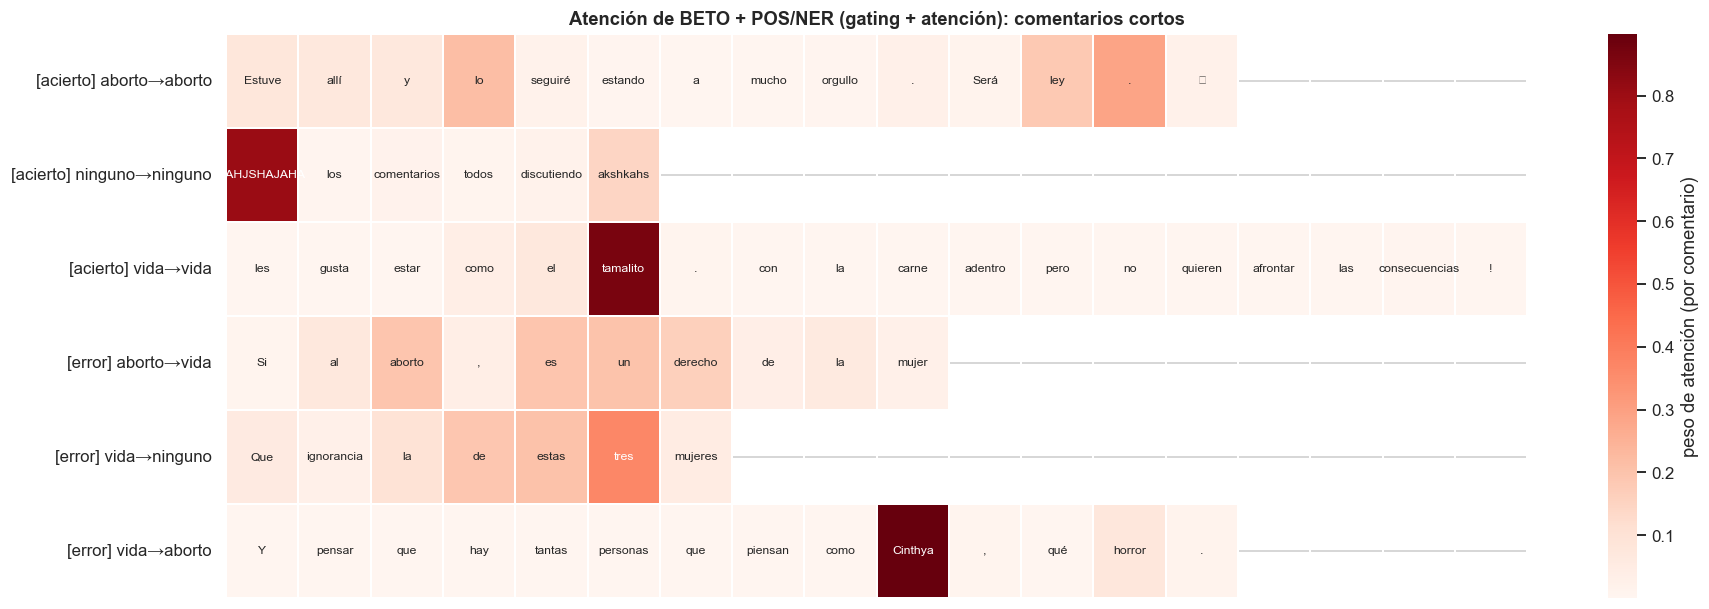

In [19]:
print(f"Valor medio de la compuerta (1 = solo flujo contextual de BETO, 0 = solo etiquetas): "
      f"{np.mean([v['gate'] for v in ATT.values()]):.3f}")

def word_attention(j):
    """Agrega la atención de subwords a nivel de palabra (sin tokens especiales) y la renormaliza."""
    st = ATT[j]; words = A[j]["words"]; w = np.zeros(len(words))
    for k, wi in enumerate(st["word_ids"]):
        if wi is not None: w[wi] += st["alpha"][k]
    return words, w / max(w.sum(), 1e-9)

def attention_figure(model_name, n_each=3, max_words=18, seed=SEED):
    pred = RESULTS[model_name]["pred"]; rng = np.random.default_rng(seed)
    cand = [j for j in ATT if 6 <= len(A[j]["words"]) <= max_words]
    ok = [j for j in cand if pred[j] == y[j]]; bad = [j for j in cand if pred[j] != y[j]]
    chosen = list(rng.permutation(ok)[:n_each]) + list(rng.permutation(bad)[:n_each])
    M = np.full((len(chosen), max_words), np.nan); S = np.full((len(chosen), max_words), "", dtype=object); rows = []
    for r, j in enumerate(chosen):
        words, w = word_attention(j)
        M[r, :len(words)] = w; S[r, :len(words)] = words
        rows.append(("[acierto] " if pred[j] == y[j] else "[error] ") + f"{LABELS[y[j]]}→{LABELS[pred[j]]}")
    fig, ax = plt.subplots(figsize=(max_words * 0.95, 0.75 * len(chosen) + 1.2))
    sns.heatmap(M, annot=S, fmt="", cmap="Reds", cbar_kws={"label": "peso de atención (por comentario)"},
                yticklabels=rows, xticklabels=False, linewidths=1, linecolor="white", annot_kws={"fontsize": 8}, ax=ax)
    ax.set_title(f"Atención de {model_name}: comentarios cortos")
    plt.yticks(rotation=0); plt.tight_layout(); plt.show()

attention_figure("BETO + POS/NER (gating + atención)")

In [20]:
part4 = ["POS 1-3 gramas + LR", "Palabras 1-2g + POS 1-3g + LR", "N-gramas con entidades (ENT_*) + LR",
         "N-gramas con entidades, sin MISC + LR", "Entidades (sin MISC) + POS 1-3g + LR",
         "BETO (fine-tuning)", "BETO + atención (sin etiquetas)", "BETO + POS/NER (gating + atención)"]
results_table(["TF-IDF (1-2 gramas) + LR"] + part4)

,Familia,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 por pliegue,IC 95 % F1 (bootstrap),F1 aborto,F1 vida,F1 ninguno
Modelo,,,,,,,,,,
TF-IDF (1-2 gramas) + LR,Línea base,0.618,0.611,0.590,0.595,0.595 ± 0.026,"[0.56, 0.63]",0.512,0.662,0.611
BETO (fine-tuning),Transformer,0.659,0.635,0.630,0.632,0.631 ± 0.031,"[0.60, 0.66]",0.515,0.686,0.695
POS 1-3 gramas + LR,Híbrido,0.529,0.505,0.503,0.504,0.503 ± 0.035,"[0.47, 0.54]",0.394,0.543,0.574
Palabras 1-2g + POS 1-3g + LR,Híbrido,0.633,0.617,0.601,0.607,0.607 ± 0.047,"[0.57, 0.64]",0.501,0.649,0.671
N-gramas con entidades (ENT_*) + LR,Híbrido,0.613,0.609,0.583,0.590,0.590 ± 0.025,"[0.56, 0.62]",0.505,0.645,0.621
"N-gramas con entidades, sin MISC + LR",Híbrido,0.609,0.601,0.580,0.586,0.586 ± 0.027,"[0.55, 0.62]",0.500,0.647,0.612
Entidades (sin MISC) + POS 1-3g + LR,Híbrido,0.633,0.620,0.602,0.609,0.608 ± 0.039,"[0.58, 0.64]",0.509,0.649,0.668
BETO + atención (sin etiquetas),Híbrido,0.659,0.630,0.636,0.633,0.633 ± 0.029,"[0.60, 0.67]",0.508,0.682,0.709
BETO + POS/NER (gating + atención),Híbrido,0.664,0.638,0.642,0.640,0.640 ± 0.029,"[0.61, 0.67]",0.524,0.685,0.711


### Comentarios · Modelos híbridos
* **N-gramas de POS** solos: F1 0.504, debajo de cualquier modelo de palabras, consistente con que la distribución de POS casi no cambia entre clases.
* **Palabras + POS** (0.607) y **entidades sin `MISC` + POS** (0.609) superan por 1 a 1.5 puntos a TF-IDF (0.595): mejora pequeña y dentro del ruido (IC [0.57, 0.64] y [0.58, 0.64]).
* **Sustituir entidades** (0.590 con todos los tipos, 0.586 conservando `MISC`) no mejora a TF-IDF: en este tema los nombres propios llevan señal (*Dios*; *Lupe*, por la influencer provida Lupe Batallán) y el NER es ruidoso.
* **BETO + POS/NER con compuerta y atención** es el mejor modelo de la tarea (F1 0.640, exactitud 0.664, IC [0.61, 0.67]), pero solo 0.7 puntos sobre la misma arquitectura sin etiquetas (0.633) y 0.8 sobre BETO simple (0.632): las etiquetas no aportan una mejora demostrable. La compuerta media es 0.61, es decir, el modelo sí mezcla cerca de 39 % de información estructural, pero eso casi no cambia sus predicciones.
* **Atención:** se concentra en palabras con carga (*ley* en *"Será ley"*, *aborto*, *derecho*), pero también en nombres propios (*Cinthya*), en palabras coloquiales (*tamalito*) y en risas escritas (*AHJSHAJAH*). Sirve para inspeccionar el modelo, no como explicación causal.

## Parte 5 · Evaluación y comparación
Métricas estándar (exactitud, precisión, recall y F1 con promedio **macro**) sobre las predicciones *out-of-fold* de los 1,000 comentarios, más la media ± desviación del F1 por pliegue
y un intervalo de confianza al 95 % por *bootstrap*.

In [21]:
results_table()

,Familia,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 por pliegue,IC 95 % F1 (bootstrap),F1 aborto,F1 vida,F1 ninguno
Modelo,,,,,,,,,,
Mayoría (referencia),Línea base,0.421,0.140,0.333,0.198,0.198 ± 0.001,"[0.19, 0.21]",0.000,0.593,0.000
BoW (unigramas) + LR,Línea base,0.623,0.598,0.593,0.592,0.591 ± 0.037,"[0.56, 0.62]",0.469,0.609,0.697
TF-IDF (1-2 gramas) + LR,Línea base,0.618,0.611,0.590,0.595,0.595 ± 0.026,"[0.56, 0.63]",0.512,0.662,0.611
Conteos POS/NER + LR,POS/NER,0.484,0.482,0.492,0.470,0.470 ± 0.017,"[0.44, 0.50]",0.370,0.454,0.585
BiLSTM + vectores de palabra,POS/NER,0.609,0.587,0.598,0.589,0.587 ± 0.026,"[0.56, 0.62]",0.503,0.571,0.692
BiLSTM + vectores + POS,POS/NER,0.612,0.588,0.593,0.586,0.585 ± 0.033,"[0.55, 0.62]",0.478,0.586,0.694
BiLSTM + vectores + POS + NER,POS/NER,0.603,0.578,0.590,0.579,0.578 ± 0.038,"[0.55, 0.61]",0.475,0.562,0.699
BETO (fine-tuning),Transformer,0.659,0.635,0.630,0.632,0.631 ± 0.031,"[0.60, 0.66]",0.515,0.686,0.695
RoBERTuito (fine-tuning),Transformer,0.650,0.630,0.648,0.635,0.635 ± 0.010,"[0.60, 0.67]",0.548,0.654,0.702


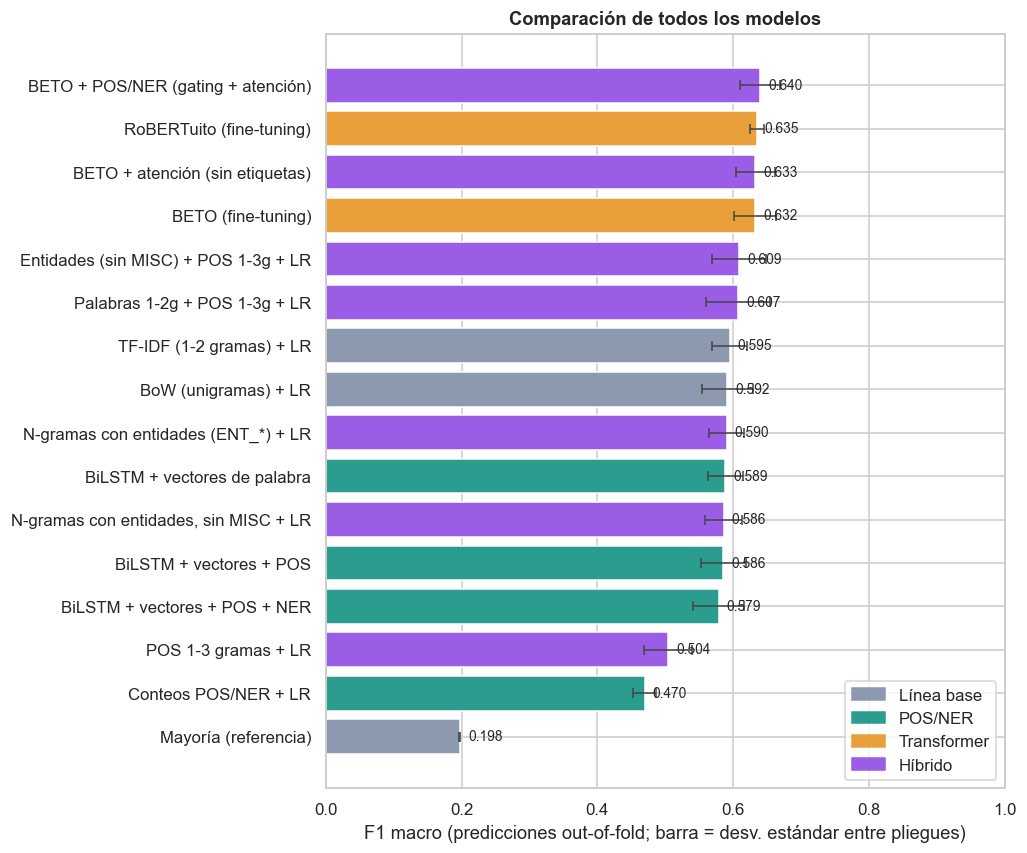

In [22]:
summ = pd.DataFrame({n: dict(**compute_metrics(y, r["pred"]), fam=r["family"], sd=r["fold_f1"].std()) for n, r in RESULTS.items()}).T
summ = summ.sort_values("f1")
fam_colors = {"Línea base": "#8D99AE", "POS/NER": "#2A9D8F", "Transformer": "#E9A03B", "Híbrido": "#9B5DE5"}
fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(summ) + 1.2))
ax.barh(summ.index, summ.f1.astype(float), xerr=summ.sd.astype(float), color=[fam_colors[f] for f in summ.fam],
        error_kw=dict(ecolor="#444", capsize=3, lw=1))
for i, v in enumerate(summ.f1.astype(float)):
    ax.text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("F1 macro (predicciones out-of-fold; barra = desv. estándar entre pliegues)")
ax.set_xlim(0, 1); ax.set_title("Comparación de todos los modelos")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_colors.values()]
ax.legend(handles, fam_colors.keys(), loc="lower right", frameon=True)
plt.tight_layout(); plt.show()

### 5.1 Matrices de confusión (normalizadas por fila)

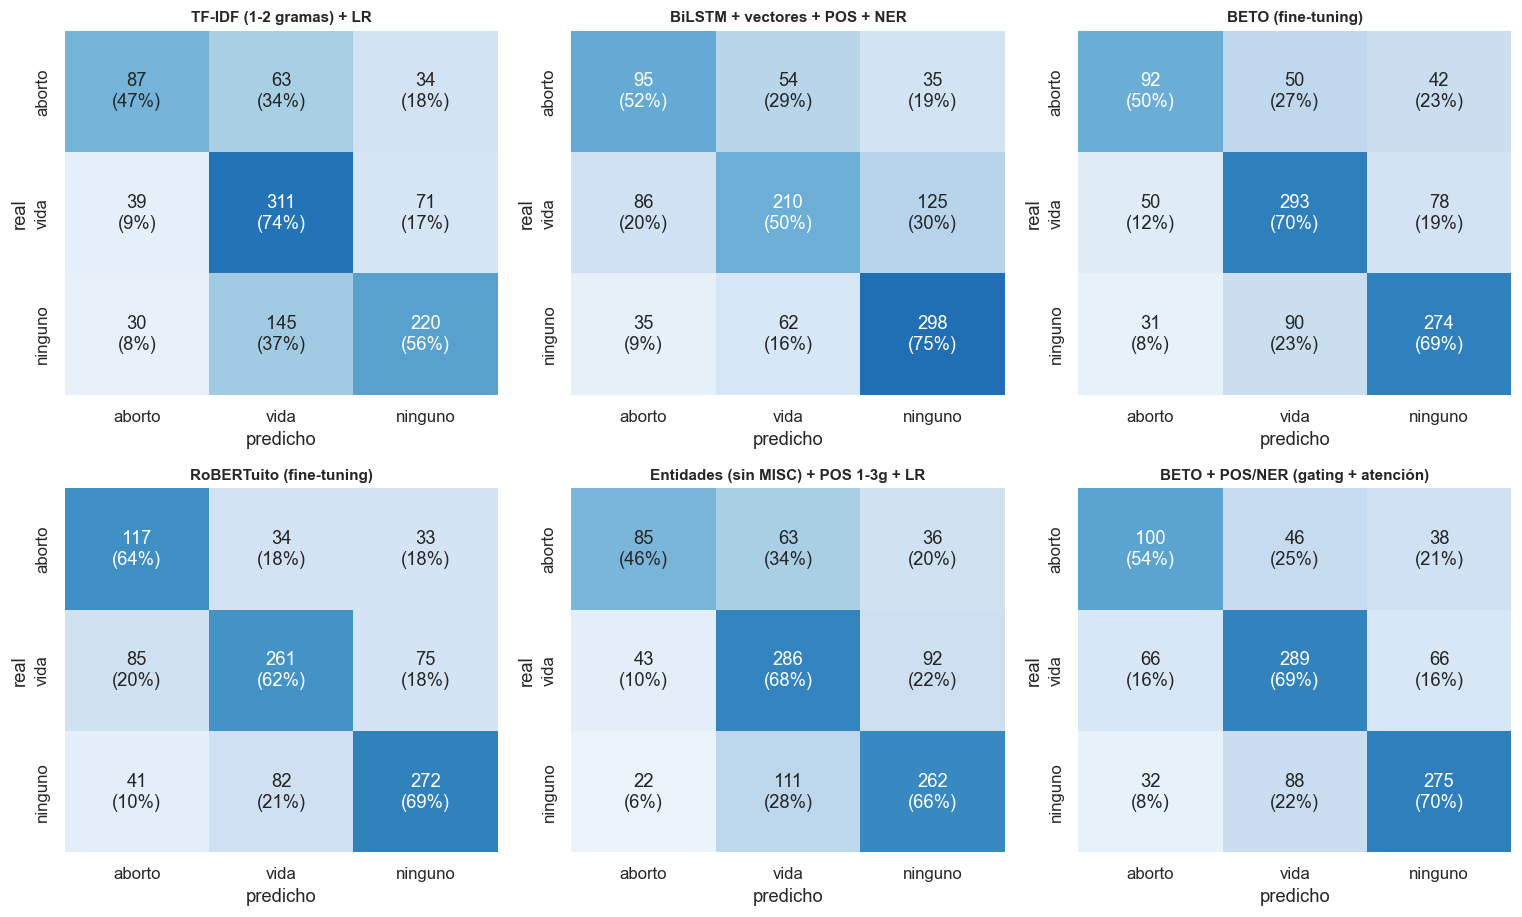

In [23]:
show = ["TF-IDF (1-2 gramas) + LR", "BiLSTM + vectores + POS + NER", "BETO (fine-tuning)", "RoBERTuito (fine-tuning)",
        "Entidades (sin MISC) + POS 1-3g + LR", "BETO + POS/NER (gating + atención)"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, n in zip(axes.ravel(), show):
    cm = confusion_matrix(y, RESULTS[n]["pred"], labels=[0, 1, 2])
    cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f"{cm[i, j]}\n({cmn[i, j]:.0%})" for j in range(3)] for i in range(3)]), fmt="",
                cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(n, fontsize=10); ax.set_xlabel("predicho"); ax.set_ylabel("real")
plt.tight_layout(); plt.show()

### Comentarios · Comparación global
* **Orden por F1 macro:** Transformers y el híbrido con BETO (0.632 a 0.640) > híbridos léxicos con POS (0.607 a 0.609) > BoW, TF-IDF, BiLSTM y n-gramas con entidades (0.579 a 0.595) > modelos de solo POS/NER (0.470 a 0.504) > referencia (0.198).
* **Qué es firme:** todos superan a la referencia; los modelos de solo etiquetas quedan claramente debajo de los de palabras; y los cuatro modelos con Transformer son los mejores por unos 4 puntos, aunque el IC del mejor ([0.61, 0.67]) apenas toca el de TF-IDF ([0.56, 0.63]). Dentro de cada familia las diferencias son ruido.
* **Matrices de confusión:** la confusión dominante es `ninguno` ↔ `vida`: TF-IDF manda a `vida` el 37 % de los `ninguno` y los Transformers entre 21 % y 23 %. `aborto` se confunde sobre todo con `vida` (18 % a 34 % según el modelo), porque usa el mismo vocabulario (*aborto*, *vida*, *bebé*) para sostener lo contrario. A diferencia de la corrida con 81 comentarios, ningún modelo colapsa hacia la clase mayoritaria.

### 5.2 Análisis de errores
¿Qué tipo de comentarios se clasifican mal? Se segmentan los 1,000 comentarios según rasgos lingüísticos observables
(longitud, presencia de entidades, vocabulario religioso, narración en primera persona) y se calcula la **tasa de error de cada modelo en cada segmento**.

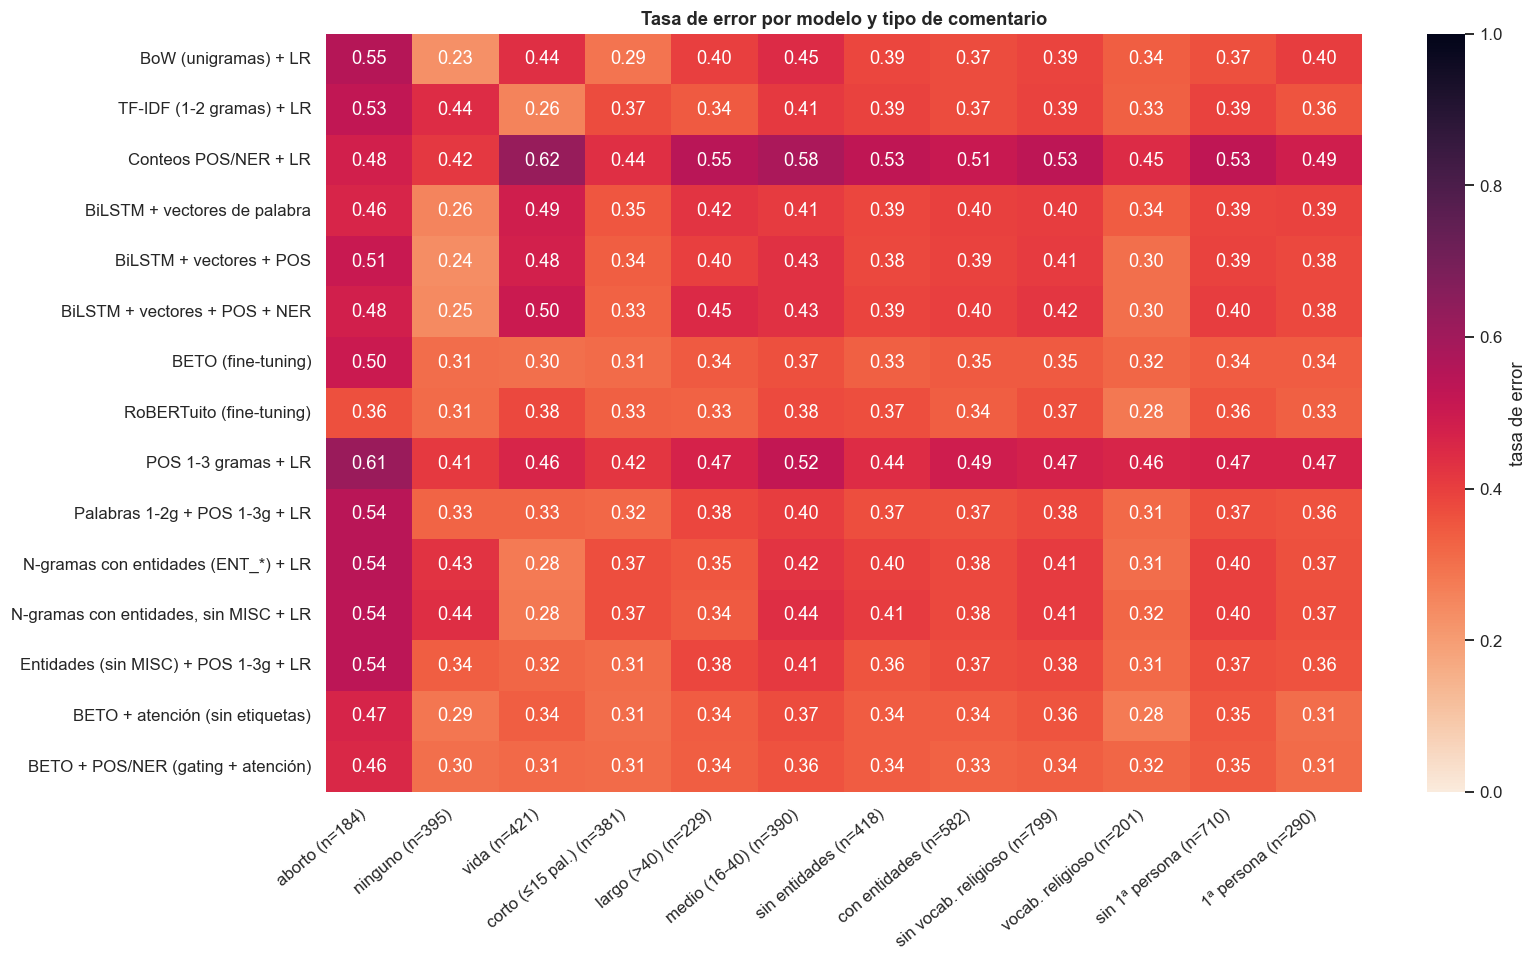

In [24]:
REL_RE = re.compile(r"\b(dios|señor|jesús|jesus|cristo|biblia|virgen|bendic\w*|oraci[oó]n|pecado|iglesia|am[eé]n|diosito|fe)\b", re.I)
FIRST_RE = re.compile(r"\b(yo|mi|mí|mis|me|soy|estoy|fui|tuve|hice|pasé|pase)\b", re.I)

seg = pd.DataFrame({
    "clase real": data.postura,
    "longitud": pd.cut(data.n_palabras, [0, 15, 40, 10**6], labels=["corto (≤15 pal.)", "medio (16-40)", "largo (>40)"]),
    "entidades": np.where(data.n_ents > 0, "con entidades", "sin entidades"),
    "religión": np.where(data.text_clean.str.contains(REL_RE), "vocab. religioso", "sin vocab. religioso"),
    "1ª persona": np.where(data.text_clean.str.contains(FIRST_RE), "1ª persona", "sin 1ª persona"),
})
MODELS = [n for n in RESULTS if not n.startswith("Mayoría")]
wrong = pd.DataFrame({n: RESULTS[n]["pred"] != y for n in MODELS})

cols = {}
for dim in seg.columns:
    for val in seg[dim].dropna().unique():
        m = (seg[dim] == val).values
        cols[f"{val} (n={m.sum()})"] = wrong[m].mean()
err_seg = pd.DataFrame(cols)
order = [c for c in err_seg.columns]
fig, ax = plt.subplots(figsize=(15, 0.42 * len(MODELS) + 2.6))
sns.heatmap(err_seg[order], annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1, cbar_kws={"label": "tasa de error"}, ax=ax)
ax.set_title("Tasa de error por modelo y tipo de comentario"); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

In [25]:
print("Tasa de error media (promedio de los modelos) por segmento:")
print(err_seg.mean().round(2).sort_values(ascending=False).to_string())

Tasa de error media (promedio de los modelos) por segmento:
aborto (n=184)                  0.51
medio (16-40) (n=390)           0.43
sin vocab. religioso (n=799)    0.40
vida (n=421)                    0.39
con entidades (n=582)           0.39
sin 1ª persona (n=710)          0.39
sin entidades (n=418)           0.39
largo (>40) (n=229)             0.39
1ª persona (n=290)              0.38
corto (≤15 pal.) (n=381)        0.35
ninguno (n=395)                 0.33
vocab. religioso (n=201)        0.33


### 5.3 Los comentarios más difíciles

In [26]:
n_wrong = wrong.sum(1)
hard = data.assign(n_modelos_fallan=n_wrong, real=data.postura,
                   pred_mas_comun=[LABELS[np.bincount([RESULTS[n]["pred"][i] for n in MODELS], minlength=3).argmax()] for i in range(len(data))])
print(f"Comentarios mal clasificados por TODOS los modelos ({len(MODELS)}): {(n_wrong == len(MODELS)).sum()}")
print(f"Comentarios que ningún modelo falla: {(n_wrong == 0).sum()}")
pd.set_option("display.max_colwidth", 140)
hard.sort_values("n_modelos_fallan", ascending=False).head(12)[["real", "pred_mas_comun", "n_modelos_fallan", "text_clean"]]\
    .assign(text_clean=lambda d: d.text_clean.str.slice(0, 135)).reset_index(drop=True)

Comentarios mal clasificados por TODOS los modelos (15): 68
Comentarios que ningún modelo falla: 154


,real,pred_mas_comun,n_modelos_fallan,text_clean
0,aborto,vida,15,Números 5:11-34 no dice nada del aborto. Miren el texto en su contexto antes de emitir información. Los que vean esto busquen y corrobo
1,aborto,ninguno,15,La SoLuCiOn Es El aMoR💙😭 sI a La ViDa 💙💙💙 *se traga un asado*
2,aborto,ninguno,15,ya somos un chingo en este planeta!!!
3,vida,ninguno,15,"6:46 Que barbaridad, ni los asesinos en serie."
4,aborto,ninguno,15,Debería haber médicos abortistas una parte nueva listo
5,aborto,vida,15,Un bebé lo es al final de un proceso de meses. Una célula recién fecundada no es un bebé ni un ser humano autónomo; es vida en potencia
6,vida,ninguno,15,Me encanta el disfraz de cristiana hahaha
7,vida,ninguno,15,Afortunadamente se cuenta con muchos videos que nos dan una idea de lo que pasa y no nos pueden engañar con títulos de videos.
8,vida,ninguno,15,"Lamentablemente, no es la primera vez que en éste canal tergiversan textos bíblicos a su conveniencia 😤"
9,vida,ninguno,15,Adopción o cuídate con preservativos y inyección o algo


**¿Cambian los POS de los comentarios mal clasificados?** Distribución de POS en aciertos vs. errores del mejor modelo.

Mejor modelo por F1 macro: BETO + POS/NER (gating + atención)


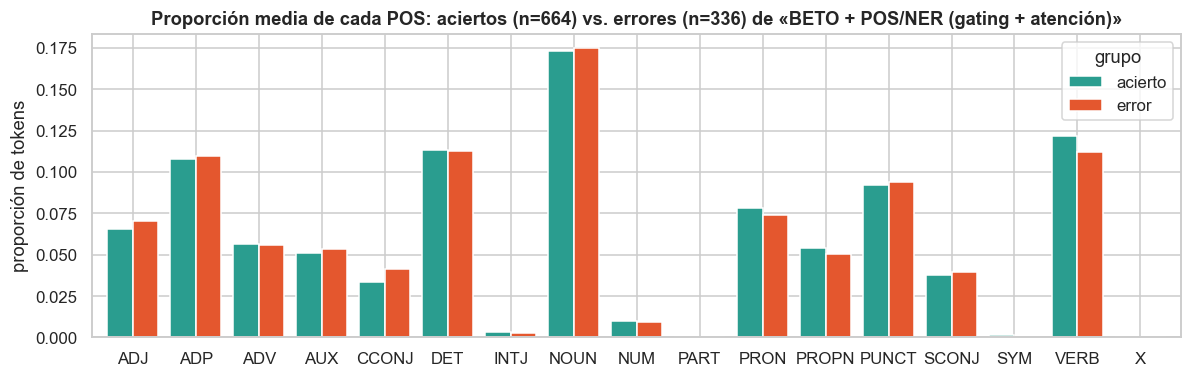

In [27]:
best = max(MODELS, key=lambda n: compute_metrics(y, RESULTS[n]["pred"])["f1"])
print("Mejor modelo por F1 macro:", best)
ok = RESULTS[best]["pred"] == y
rows = []
for a, o in zip(A, ok):
    n = len(a["pos"]); cnt = np.bincount(a["pos_id"], minlength=len(UPOS)) / n
    rows.append(dict(grupo="acierto" if o else "error", **dict(zip(UPOS, cnt))))
pg = pd.DataFrame(rows).groupby("grupo")[UPOS].mean().T[["acierto", "error"]]
ax = pg.plot.bar(figsize=(11, 3.6), color=["#2A9D8F", "#E4572E"], width=0.8)
ax.set_title(f"Proporción media de cada POS: aciertos (n={ok.sum()}) vs. errores (n={(~ok).sum()}) de «{best}»")
ax.set_ylabel("proporción de tokens"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### Comentarios · Errores
* **Por clase:** `aborto` es la más difícil (error medio de 51 %), seguida de `vida` (39 %) y `ninguno` (33 %).
* **Por longitud:** los cortos (15 palabras o menos) fallan menos (35 %) que los medianos (43 %) y los largos (39 %). Muchos cortos son `ninguno` evidentes (comentarios sobre el video), mientras que los medianos mezclan argumentos de ambos lados.
* **Vocabulario religioso:** 33 % de error frente a 40 % sin él; es una señal fuerte de `vida`. Tener entidades o hablar en primera persona no cambia la tasa (39 % frente a 39 %; 38 % frente a 39 %).
* **POS de los errores** del mejor modelo: casi idénticos a los de los aciertos (ligeramente más adjetivos y conjunciones, menos verbos y pronombres). La sintaxis no explica los errores.
* **Casos más difíciles** (68 comentarios fallados por los 15 modelos; 154 que ningún modelo falla):
  * Negación con el vocabulario del otro bando: *"NO estoy de acuerdo con la pena de muerte. NO estoy de acuerdo con la interrupción voluntaria del embarazo..."* es `vida` y la mayoría predice `aborto`.
  * Sarcasmo: *"La SoLuCiOn Es El aMoR 💙 sI a La ViDa 💙 \*se traga un asado\*"* se burla de los provida (`aborto`), aunque literalmente dice *sí a la vida*.
  * Postura implícita o que requiere conocimiento del mundo: *"ya somos un chingo en este planeta"* (la sobrepoblación como argumento a favor), *"Adopción o cuídate con preservativos"* (alternativas al aborto, `vida`), *"Que barbaridad, ni los asesinos en serie"*.
  * Argumentos con citas: *"Números 5:11-34 no dice nada del aborto..."*.
  * Etiquetas discutibles: casos como *"Me encanta el disfraz de cristiana hahaha"* (etiquetado `vida`) admiten otra lectura. Con 23 % de desacuerdo entre Haiku y las etiquetas manuales, parte del error medido es de la etiqueta y no del modelo.

## Reporte resumen

**Equipo 3:** Lambda Remiel Heredia Pérez y Diego Octavio Pérez Urbina.

**Problema.** Clasificar la postura de comentarios de YouTube en español sobre el aborto en tres clases: `vida` (en contra), `aborto` (a favor de la legalización o de que la mujer decida) y `ninguno` (sin postura). Se compararon 15 configuraciones en cuatro familias: línea base (BoW/TF-IDF), características POS/NER (conteos y BiLSTM), *fine-tuning* de Transformers (BETO y RoBERTuito) y modelos híbridos (n-gramas de POS, n-gramas con entidades y BETO + POS/NER con compuerta y atención).

**Datos.** 1,000 comentarios de 96 videos, obtenidos con la YouTube Data API. Etiquetar por la postura del video resultó inservible (31 % de acierto contra etiquetas manuales), así que se etiquetó por contenido: 176 comentarios a mano y 824 con Claude Haiku, validado a ciegas contra los manuales (77 % de acuerdo, kappa 0.62). Distribución: 42 % `vida`, 40 % `ninguno`, 18 % `aborto`. No se logró el "mitad y mitad": aun en videos proelección la mayoría de los comentarios son provida, y `aborto` quedó como clase minoritaria pese a priorizar comentarios con frases proelección.

**Protocolo.** Validación cruzada estratificada de 5 pliegues (los mismos para todos los modelos), predicciones *out-of-fold*, F1 macro como métrica principal, IC 95 % por *bootstrap* y pesos por clase. Ejecutado en una GPU RTX 3060 (66 min).

| Modelo | Accuracy | F1 macro | IC 95 % F1 | F1 `aborto` |
|---|---|---|---|---|
| Mayoría (referencia) | 0.421 | 0.198 | [0.19, 0.21] | 0.00 |
| BoW + LR | 0.623 | 0.592 | [0.56, 0.62] | 0.47 |
| TF-IDF 1-2g + LR | 0.618 | 0.595 | [0.56, 0.63] | 0.51 |
| Conteos POS/NER + LR | 0.484 | 0.470 | [0.44, 0.50] | 0.37 |
| BiLSTM + vectores | 0.609 | 0.589 | [0.56, 0.62] | 0.50 |
| BiLSTM + vectores + POS + NER | 0.603 | 0.579 | [0.55, 0.61] | 0.48 |
| BETO (*fine-tuning*) | 0.659 | 0.632 | [0.60, 0.66] | 0.52 |
| RoBERTuito (*fine-tuning*) | 0.650 | 0.635 | [0.60, 0.67] | **0.55** |
| POS 1-3 gramas + LR | 0.529 | 0.504 | [0.47, 0.54] | 0.39 |
| Entidades (sin `MISC`) + POS + LR | 0.633 | 0.609 | [0.58, 0.64] | 0.51 |
| BETO + atención (sin etiquetas) | 0.659 | 0.633 | [0.60, 0.67] | 0.51 |
| BETO + POS/NER (compuerta + atención) | **0.664** | **0.640** | [0.61, 0.67] | 0.52 |

**Hallazgos principales.**
1. **Los Transformers son los mejores** (F1 macro de 0.63 a 0.64), unos 4 puntos sobre la línea base. La ventaja es modesta pero consistente en los cuatro modelos basados en BETO o RoBERTuito.
2. **El tamaño del corpus cambió las conclusiones.** Con los primeros 81 comentarios BoW era el mejor modelo y los Transformers no acertaban un solo `aborto`; con 1,000, la línea base sube de 0.51 a 0.59 y los Transformers de 0.43 a 0.63.
3. **Las etiquetas POS/NER no aportan de forma demostrable:** no mejoran la BiLSTM (0.589 → 0.579) ni a BETO (0.633 → 0.640, dentro del ruido), y solas quedan muy por debajo de las palabras. La distribución de POS es casi idéntica entre posturas y el NER de spaCy es ruidoso en texto informal.
4. **El preentrenamiento en redes sociales ayuda con la clase minoritaria:** RoBERTuito tiene el mejor F1 de `aborto` (0.55, recall 64 %), aunque en F1 macro empata con BETO.

**Fortalezas y debilidades.** *BoW/TF-IDF*: segundos de cómputo, interpretables y a solo 4 puntos del mejor modelo, pero no entienden negación ni sarcasmo. *POS/NER + BiLSTM*: no mejoran a las palabras y la BiLSTM fue lo más lento de entrenar. *Transformers*: mejores en todas las clases y en la minoritaria, a cambio de GPU y de menos interpretabilidad. *Híbrido con compuerta y atención*: el mejor número y el único con atención inspeccionable, pero su ventaja sobre BETO simple es ruido.

**Patrones de error.** (i) `aborto` es la clase más difícil (51 % de error medio) porque comparte vocabulario con `vida`; (ii) la confusión más frecuente es `ninguno` ↔ `vida`; (iii) los comentarios que fallan todos los modelos son negaciones (*"NO estoy de acuerdo con la interrupción voluntaria del embarazo"*), sarcasmo, posturas implícitas que requieren conocimiento del mundo y etiquetas discutibles.

**Limitaciones y siguientes pasos.** El 82 % de las etiquetas proviene de un modelo de lenguaje con 77 % de acuerdo con las manuales, lo que pone un techo a todas las métricas; `aborto` está subrepresentada y en parte seleccionada por frases explícitas; y los resultados de las redes neuronales varían alrededor de ± 0.03 entre corridas. Los pasos con más retorno serían revisar a mano los 68 comentarios que fallan todos los modelos y los desacuerdos entre Haiku y las etiquetas manuales, y ampliar la clase `aborto` con fuentes de público proelección.